In [2]:
import pandas as pd

panel = pd.read_csv("../data/clean_data/zh_regression_panel.csv")

df = panel[panel["year"] >= 2011]
df = df[df["year"] <= 2022]
#keep only the rows within relevant time period

print(df.shape)
print(df["year"].min(), df["year"].max())

(1920, 10)
2011 2022


In [3]:
print(df.isna().sum())

GDENR                       0
year                        0
turnout                     0
foreigner_rate              0
social_assistance_rate    171
unemployment_rate         157
tertiary_share            960
median_income              16
old_age_ratio               0
population_density          7
dtype: int64


In [4]:
df = df.drop(columns=["tertiary_share"])
#drop tertiary share since to limiting, will be used as check
df = df.dropna()

print(df.shape)
print(df["GDENR"].nunique())

(1677, 9)
158


In [6]:
import numpy as np

df["log_median_income"] = np.log(df["median_income"])
df["log_population_density"] = np.log(df["population_density"])

print(df[["median_income", "log_median_income", "population_density", "log_population_density"]].head())
df.head()

    median_income  log_median_income  population_density  \
49        59200.0          10.988677               242.8   
50        60300.0          11.007087               248.9   
51        58600.0          10.978490               250.3   
52        59700.0          10.997087               248.0   
53        57700.0          10.963012               252.4   

    log_population_density  
49                5.492238  
50                5.517051  
51                5.522660  
52                5.513429  
53                5.531015  


,GDENR,year,turnout,foreigner_rate,social_assistance_rate,unemployment_rate,median_income,old_age_ratio,population_density,log_median_income,log_population_density
49,1,2011,51.520000,13.6,0.6,1.4,59200.0,23.9,242.8,10.988677,5.492238
50,1,2012,43.664167,14.4,0.8,1.3,60300.0,24.2,248.9,11.007087,5.517051
51,1,2013,51.252727,14.3,0.6,1.8,58600.0,24.3,250.3,10.978490,5.522660
52,1,2014,57.996667,12.9,0.6,1.3,59700.0,25.5,248.0,10.997087,5.513429
53,1,2015,48.715000,13.0,0.8,1.8,57700.0,26.0,252.4,10.963012,5.531015


In [7]:
variables = ["turnout", "foreigner_rate", "social_assistance_rate", "unemployment_rate",
             "median_income", "old_age_ratio", "population_density"]

summary = df[variables].describe()
print(summary.round(1))

       turnout  foreigner_rate  social_assistance_rate  unemployment_rate  \
count   1677.0          1677.0                  1677.0             1677.0   
mean      50.3            20.0                     2.0                2.0   
std        7.9             8.0                     1.2                0.7   
min       29.2             5.6                     0.0                0.6   
25%       44.8            13.7                     1.1                1.5   
50%       50.6            19.3                     1.7                1.9   
75%       55.9            25.4                     2.6                2.4   
max       73.8            48.1                     6.9                4.9   

       median_income  old_age_ratio  population_density  
count         1677.0         1677.0              1677.0  
mean         55963.6           28.7               881.5  
std           7196.8            6.0               809.2  
min          40900.0           14.4                62.0  
25%          513

In [8]:
corr_vars = ["turnout", "foreigner_rate", "social_assistance_rate", "unemployment_rate",
             "log_median_income", "old_age_ratio", "log_population_density"]

correlations = df[corr_vars].corr()
print(correlations.round(2))

                        turnout  foreigner_rate  social_assistance_rate  \
turnout                    1.00           -0.45                   -0.48   
foreigner_rate            -0.45            1.00                    0.66   
social_assistance_rate    -0.48            0.66                    1.00   
unemployment_rate         -0.32            0.69                    0.63   
log_median_income          0.50           -0.21                   -0.54   
old_age_ratio              0.46           -0.19                   -0.21   
log_population_density    -0.21            0.72                    0.49   

                        unemployment_rate  log_median_income  old_age_ratio  \
turnout                             -0.32               0.50           0.46   
foreigner_rate                       0.69              -0.21          -0.19   
social_assistance_rate               0.63              -0.54          -0.21   
unemployment_rate                    1.00              -0.37          -0.23   
log_

In [9]:
import matplotlib.pyplot as plt

turnout_per_year = df.groupby("year")["turnout"].mean()

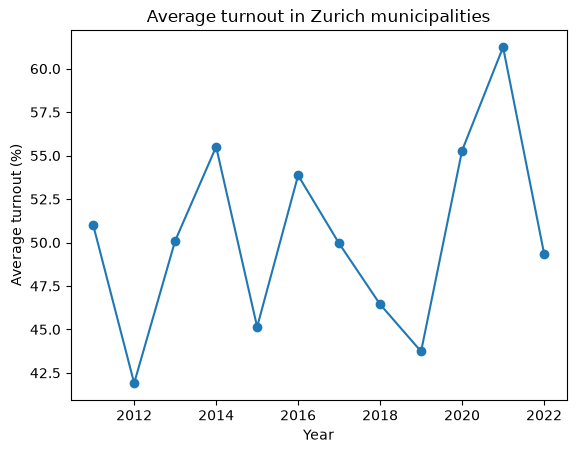

In [10]:
turnout_per_year.plot(marker="o")
plt.xlabel("Year")
plt.ylabel("Average turnout (%)")
plt.title("Average turnout in Zurich municipalities")
plt.show()

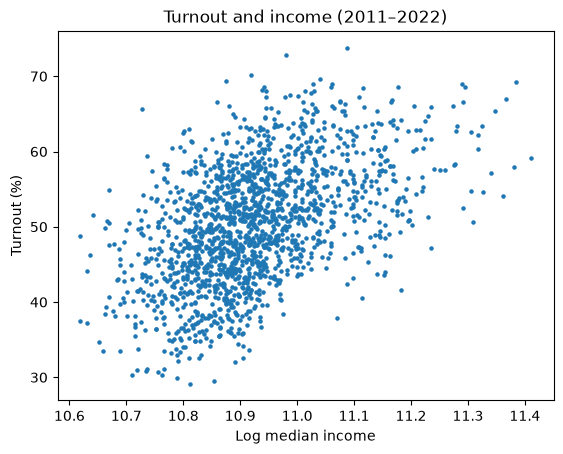

In [11]:
plt.scatter(df["log_median_income"], df["turnout"], s=5)
plt.xlabel("Log median income")
plt.ylabel("Turnout (%)")
plt.title("Turnout and income (2011–2022)")
plt.show()

In [12]:
full = panel[panel["year"] >= 2011]
full = full[full["year"] <= 2022]
#relevant time frame

In [17]:
dropped = full[full["social_assistance_rate"].isna()| full["unemployment_rate"].isna()| full["median_income"].isna()| full["population_density"].isna()]
#get dropped rows for comparison
print("kept:", len(df), " dropped:", len(dropped))
print("Kept:", df[["turnout", "foreigner_rate", "social_assistance_rate", "unemployment_rate",
             "median_income", "old_age_ratio", "population_density"]].median())
print("Dropped:", dropped[["turnout", "foreigner_rate", "social_assistance_rate", "unemployment_rate",
             "median_income", "old_age_ratio", "population_density"]].median())

kept: 1677  dropped: 243
Kept: turnout                      50.578333
foreigner_rate               19.300000
social_assistance_rate        1.700000
unemployment_rate             1.900000
median_income             54800.000000
old_age_ratio                28.300000
population_density          607.500000
dtype: float64
Dropped: turnout                      54.29
foreigner_rate               10.30
social_assistance_rate        1.20
unemployment_rate             1.50
median_income             55000.00
old_age_ratio                29.10
population_density          131.45
dtype: float64
